# What makes the original Transformer AR worse? Ablations on S7_k02345 (seed 42)

Three variants of the ORIGINAL Transformer AR (same sequence, delimiters, segment embeddings, teacher forcing and
token-by-token decoding). Each changes one thing, or both:

| model | change |
|---|---|
| `ar_slotpos` | **no 1-D position table pos(t)**; op tokens get an op-slot embedding instead; every other token keeps segment + row/col |
| `ar_digiteos` | **11-way output head** (digits 0–9 + EOS) instead of the full 20-token vocabulary; loss on 36 digits + EOS and 37 decoding steps, as in the original |
| `ar_slotpos_digiteos` | both |

Under the same seed, every other tensor starts from exactly the original AR's initial values. The slot embedding
starts from the original pos(t) rows of the op slots, and the 11-way head starts from the original head's digit and
EOS rows.
Same data stream, 20,000 updates, and sampled evaluation of the LAST checkpoint on the same test records as notebooks
23 / 29.

The final cell compares them with the original AR (23b), query AR (29b, if finished) and causal encoder (23b):
* accuracy by test k;
* singletons by operation and slot;
* k = 6 failures that equal "one operation dropped".

The runs are resumable. To go faster, open a second copy of this notebook and give the two copies disjoint
`RUN_MODELS` lists.

**Send back `AR_Ablation_S7_k02345_Review.ipynb`.**


In [1]:
# --- 2. Bootstrap: locate or clone the PRIVATE repository (credentials are never printed or stored) ---
import base64, importlib.util, os, pathlib, subprocess, sys

REPO_URL = "https://github.com/zhexuandliu/Decompositionality.git"
REPO_BRANCH = "main"
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ

def _find_repo():
    candidates = [pathlib.Path("/content/Decompositionality"), pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
    for p in candidates:
        if (p / "src" / "decompositionality").is_dir():
            return p.resolve()
    return None

REPO_DIR = _find_repo()
if REPO_DIR is None:
    token = None
    if IN_COLAB:
        try:
            from google.colab import userdata
            token = userdata.get("GITHUB_TOKEN")
        except Exception:
            token = None
    if not token:
        import getpass
        token = getpass.getpass("GitHub token with read access to the private repo (input hidden): ")
    # Pass the credential through environment-scoped git config (not the URL, not the command line,
    # not persisted in .git/config).
    _hdr = "AUTHORIZATION: basic " + base64.b64encode(f"x-access-token:{token}".encode()).decode()
    _env = dict(os.environ, GIT_TERMINAL_PROMPT="0", GIT_CONFIG_COUNT="1",
                GIT_CONFIG_KEY_0="http.https://github.com/.extraheader", GIT_CONFIG_VALUE_0=_hdr)
    REPO_DIR = pathlib.Path("/content/Decompositionality" if IN_COLAB else "Decompositionality").resolve()
    _r = subprocess.run(["git", "clone", "--depth", "1", "--branch", REPO_BRANCH, REPO_URL, str(REPO_DIR)],
                        env=_env, capture_output=True, text=True)
    del token, _hdr, _env
    if _r.returncode != 0:
        raise RuntimeError("git clone failed (check the GITHUB_TOKEN secret / repo access):\n" + _r.stderr[-2000:])

if str(REPO_DIR / "src") not in sys.path:
    sys.path.insert(0, str(REPO_DIR / "src"))
for _mod in ("numpy", "pandas", "matplotlib", "torch"):
    if importlib.util.find_spec(_mod) is None:  # Colab already ships these; never reinstall torch/CUDA here
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _mod], check=True)
REPO_COMMIT = subprocess.run(["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()
print("Repository:", REPO_DIR, "| commit:", REPO_COMMIT or "unknown")


Repository: /content/Decompositionality | commit: aa09616c83b00f28d19da05ae6049f20369e7e3c


In [2]:
# --- CONFIGURATION -------------------------------------------------------------------------------------------------
MODE = os.environ.get("DECOMP_MODE", "full")
SEED = 42
RUN_CONDITIONS = ["S7_k02345"]
RUN_MODELS = ["ar_slotpos", "ar_digiteos", "ar_slotpos_digiteos"]
STEPS = 20000
SUBDIR = "S7_support_sweep_20k_v1"                # same folder as notebooks 23 / 27 / 29 (model subfolders differ)
EVAL_PLAN = {"n_single_grids": 1000, "n_seen_per_k": 5000, "n_long_per_k": 20000}
USE_DRIVE = IN_COLAB
RESULTS_ROOT = os.environ.get("DECOMP_RESULTS_ROOT") or (
    "/content/drive/MyDrive/decompositionality_results" if USE_DRIVE else str(REPO_DIR / "results"))
DEVICE = os.environ.get("DECOMP_DEVICE", "auto")
# -----------------------------------------------------------------------------------------------------------------
if USE_DRIVE and IN_COLAB and RESULTS_ROOT.startswith("/content/drive"):
    from google.colab import drive
    drive.mount("/content/drive")
import pandas as pd
from IPython.display import display
pd.set_option("display.max_rows", 500); pd.set_option("display.max_columns", 60); pd.set_option("display.width", 250)
from decompositionality import longk as LK, longk_exp as LX, ar_ablation as AB
print("results ->", LX.family_root(RESULTS_ROOT, MODE, SUBDIR))


Mounted at /content/drive
results -> /content/drive/MyDrive/decompositionality_results/S7_support_sweep_20k_v1


In [ ]:
# --- Train (20,000 updates) + sampled LAST-checkpoint evaluation (resumable) ---------------------------------------
status = LX.run_queue(RESULTS_ROOT, MODE, SEED, RUN_CONDITIONS, RUN_MODELS, repo_dir=str(REPO_DIR), device=DEVICE,
                      subdir=SUBDIR, steps=STEPS if MODE == "full" else None, sampled_plan=EVAL_PLAN)
display(status)


# Transformer AR ablations on S7_k02345 (seed 42, LAST checkpoint, 20,000 updates)
Trained k = 0,2,3,4,5 in 7 slots; held out: singletons (k=1) at every slot, k=6, k=7. References: query AR (29b) and causal encoder (23b).


### Availability


,model,label,status
0,transformer_ar,original AR,ok
1,ar_slotpos,AR − pos(t),ok
2,ar_digiteos,AR + 11-way head (digits+EOS),ok
3,ar_slotpos_digiteos,AR − pos(t) + 11-way head,ok
4,ar_slotpos_digiteos_target,AR − pos(t) + 11-way head + target coords,no ARTIFACT
5,nexttoken_ar,"query AR, next-token feedback",no ARTIFACT
6,query_ar,query AR,ok
7,causal_encoder,causal encoder,ok



### 1. Exact accuracy by test k (k=1 = singletons over all slots)


model,k,role,original AR,AR − pos(t),AR + 11-way head (digits+EOS),AR − pos(t) + 11-way head,query AR,causal encoder
0,0,trained,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
1,1,singleton,0.3305,0.0923,0.3491,0.3384,1.0000,1.0000
2,2,trained,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
3,3,trained,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
4,4,trained,1.0000,0.9998,1.0000,1.0000,1.0000,1.0000
5,5,trained,1.0000,0.9996,1.0000,1.0000,1.0000,1.0000
6,6,+1 step,0.0136,0.0400,0.0023,0.2115,1.0000,0.9495
7,7,+2 step,0.0024,0.1121,0.0009,0.0048,0.9964,0.4642



### 2a. Singleton accuracy by operation


... (2 outputs left out)

model,op,slot,original AR,AR − pos(t),AR + 11-way head (digits+EOS),AR − pos(t) + 11-way head,query AR,causal encoder
0,A,1,0.000,0.601,0.000,0.000,1.0,1.0
1,A,2,0.000,0.106,0.000,0.000,1.0,1.0
2,A,3,0.000,0.165,0.000,0.000,1.0,1.0
3,A,4,0.000,0.029,0.000,0.000,1.0,1.0
4,A,5,0.000,0.025,0.000,0.015,1.0,1.0
5,A,6,0.000,0.000,0.051,0.042,1.0,1.0
6,A,7,0.000,0.000,1.000,0.846,1.0,1.0
7,B,1,0.958,0.094,0.301,1.000,1.0,1.0
8,B,2,0.984,0.094,0.993,1.000,1.0,1.0
9,B,3,0.999,0.094,1.000,1.000,1.0,1.0



### 3. k=6 failures that equal the word with ONE operation dropped (counts; 'drop #i' = i-th operation)


,model,k=6 records,failed,invalid outputs,drop #1,drop #2,drop #3,drop #4,drop #5,drop #6,drop some op / failed
0,original AR,20000,19729,0,1102,1003,1514,4310,12512,4404,0.634
1,AR − pos(t),20000,19201,4,1533,2500,4079,6374,3794,1621,0.484
2,AR + 11-way head (digits+EOS),20000,19954,0,966,931,1295,3576,9836,3909,0.493
3,AR − pos(t) + 11-way head,20000,15770,0,379,433,974,2217,3017,1752,0.198
4,query AR,20000,1,0,0,0,0,0,0,0,0.000
5,causal encoder,20000,1010,0,0,0,0,0,0,0,0.000



### Accuracy vs test k


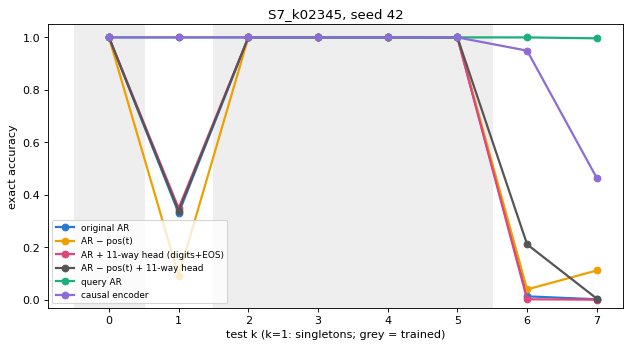

REVIEW FILE: /content/drive/MyDrive/decompositionality_results/S7_support_sweep_20k_v1/report/seed_42_ar_ablation/AR_Ablation_S7_k02345_Review.ipynb
REVIEW FILE TO SEND BACK: /content/drive/MyDrive/decompositionality_results/S7_support_sweep_20k_v1/report/seed_42_ar_ablation/AR_Ablation_S7_k02345_Review.ipynb


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
# --- Comparison (reads saved predictions only; rerun after all runs finish) ---------------------------------------
rp = AB.report(RESULTS_ROOT, MODE, SEED)
print("REVIEW FILE TO SEND BACK:", rp)
if IN_COLAB and rp:
    from google.colab import files
    files.download(str(rp))
